# 03 · Layout damage, reproduced locally — and why XEB is not fidelity

**The campaign finding.** Every *permutation* mutation (relabelling which qubit sits at which MPS site) collapsed
the cloud `mps.cpu` XEB — with depth-monotone damage (deep circuits worst) — although a relabelling leaves the
ideal output distribution unchanged. The campaign log reads it as χ-dependent *layout damage*: a fidelity lever,
not a symmetry.

**Bottom line** (numbers in the last section): the campaign's 20-qubit circuits regenerate byte-for-byte; an
independent MPS matches the cloud closely for the identity layout and in trend only under permutation; the collapse is
entanglement the relabelled chain must carry plus truncation accumulated along SWAP routes; and under heavy truncation
normalized linear XEB overstates fidelity and can exceed 1, in the cloud data too.

**What this notebook does — locally, no API key:**
1. Regenerates the campaign's own 13 twenty-qubit train/val circuits from their hard-coded seeds and checks them
   **byte-for-byte** against the frozen suite manifest — circuits (QPY sha256) *and* exact-probability truth files.
2. Re-simulates them with an **independent** 138-line numpy MPS (`mps_lite.py`, shares no code with the campaign)
   and compares per-circuit XEB with the cloud jobs, for the identity layout and for the permutations the arms tried.
3. Explains the damage with the exact state's entanglement across each cut of the chain.
4. Shows that **normalized linear XEB overstates true state fidelity** under layout damage — even exceeding the
   exact sampler's score on shallow circuits. This is closely related to the XEB-spoofing issue of Barak, Chou & Gao
   (arXiv:2005.02421) and Gao et al. (arXiv:2112.01657), observed here inside our own metric.
5. Shows that a structure-aware proposer (graph-bandwidth ordering) undoes the damage in one step.

Resource note: everything stays ≤ 20 qubits (2²⁰-amplitude statevectors, 16 MB), BLAS capped at 2 threads; the
full notebook runs in about ten minutes on a laptop CPU.

In [1]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "2")
import hashlib, io, json, time, collections
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from qiskit import QuantumCircuit, qpy
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import random_unitary, Statevector
import nbcommon as C
from mps_lite import MPS, gates_from_qiskit, normalized_xeb

C.style()
B = C.load_bundle()
MAN = B.json("suite/MANIFEST.json")
T0 = time.time()

# --- verbatim logic of the campaign generator (prototype src/circuits.py::rcs_circuit / permuted)
def rcs_circuit(n_qubits, depth, seed):
    qc = QuantumCircuit(n_qubits, name=f"rcs_n{n_qubits}_d{depth}_s{seed}")
    for d in range(depth):
        for q in range(n_qubits):
            h = int(hashlib.sha256(f"{seed}:{d}:{q}:h".encode()).hexdigest(), 16)
            qc.u((h % 628) / 100.0, ((h >> 10) % 628) / 100.0, ((h >> 20) % 628) / 100.0, q)
        even = d % 2 == 0
        pairs = ([(q, q + 1) for q in range(0, n_qubits - 1, 2)] if even
                 else [(q, q + 1) for q in range(1, n_qubits - 1, 2)])
        for a, b in pairs:
            u = random_unitary(4, seed=(seed * 1_000_003 + d * 1_009 + a * 7 + 1) % (2**31))
            qc.append(UnitaryGate(u.data), [a, b])
    return qc

def permuted(qc, perm):
    """Logical qubit L -> site perm[L] (campaign semantics)."""
    out = QuantumCircuit(qc.num_qubits, name=f"{qc.name}_perm")
    for inst in qc.data:
        out.append(inst.operation, [perm[qc.find_bit(b).index] for b in inst.qubits], [])
    return out

def perm_of(n, seed):                     # src/harness.py::perm_of
    return [int(x) for x in np.random.default_rng(seed).permutation(n)]

def permute_state(sv, perm):
    """Exact state of permuted(qc, perm), from the exact state of qc (pure axis relabelling)."""
    n = len(perm)
    t = sv.reshape([2] * n).transpose(list(range(n))[::-1])        # axis k = qubit k
    inv = [0] * n
    for L, s in enumerate(perm):
        inv[s] = L
    t = t.transpose(inv)                                            # site s carries logical inv[s]
    return t.transpose(list(range(n))[::-1]).reshape(-1)

## 1 · The campaign's 20-qubit circuits, regenerated and checked byte-for-byte

In [2]:
circs = sorted([c for c in MAN["circuits"] if c["n"] == 20 and c["split"] in ("train", "val")],
               key=lambda c: (c["depth"], c["seed"]))
qpy_ok = truth_ok = 0
for c in circs:
    qc = rcs_circuit(20, c["depth"], c["seed"])
    buf = io.BytesIO(); qpy.dump(qc, buf, version=13)
    qpy_ok += hashlib.sha256(buf.getvalue()).hexdigest() == c["sha256"]
    sv = np.asarray(Statevector.from_instruction(qc).data)          # same method as src/sim_exact.py
    f = io.BytesIO(); np.save(f, (np.abs(sv) ** 2).astype(np.float32))
    truth_ok += hashlib.sha256(f.getvalue()).hexdigest() == c["truth_sha256"]
print(f"{len(circs)} circuits (n=20, train+val; depths {sorted(collections.Counter(c['depth'] for c in circs).items())})")
print(f"QPY sha256 == frozen manifest:          {qpy_ok}/{len(circs)}")
print(f"exact-truth .npy sha256 == manifest:     {truth_ok}/{len(circs)}   ({time.time() - T0:.0f}s)")

# sanity checks of the local tools on a 10-qubit circuit (chi=32 is exact at n=10)
q10 = rcs_circuit(10, 8, 7); sv10 = np.asarray(Statevector.from_instruction(q10).data)
p10 = perm_of(10, 23)
assert np.allclose(permute_state(sv10, p10), np.asarray(Statevector.from_instruction(permuted(q10, p10)).data))
for qq in (q10, permuted(q10, p10)):
    ref = np.asarray(Statevector.from_instruction(qq).data)
    assert abs(abs(np.vdot(ref, MPS(10, 32).run(gates_from_qiskit(qq)).to_statevector())) ** 2 - 1) < 1e-9
print("sanity: permute_state == qiskit on the permuted circuit; MPS at exact bond dimension has fidelity 1 (identity and permuted)")

13 circuits (n=20, train+val; depths [(4, 3), (8, 4), (12, 3), (16, 3)])
QPY sha256 == frozen manifest:          13/13
exact-truth .npy sha256 == manifest:     13/13   (29s)
sanity: permute_state == qiskit on the permuted circuit; MPS at exact bond dimension has fidelity 1 (identity and permuted)


## 2 · Local MPS vs the cloud, configuration by configuration

Cloud values are the per-circuit normalized XEB of the campaign's `mps.cpu` jobs, read from the round records
(shot allocation printed below). Local values are the **infinite-shot** normalized XEB of our MPS state, plus its exact
fidelity F = |⟨ψ_exact|ψ_MPS⟩|², which the cloud jobs cannot report. Identity layout: χ = 64 (G3 baseline) and
χ = 32/128/256 (G3 χ sweep, val circuits). Permutation rounds: the table printed below lists every one, and which are
re-simulated here. Flywheel round 4 is excluded everywhere: its scores are invalid (since-fixed unpermutation bug,
`runs/flywheel/20261006T131302Z_r4/NOTE-BUG.md` in the campaign repo). Three control rounds are not re-simulated, to
keep the runtime near ten minutes; they enter only the cloud-only count in section 4.

In [3]:
runs = {p.parent.name: json.loads(p.read_text()) for p in sorted(B.path("runs/flywheel").glob("*/metrics.json"))}
cloud = {}
def add_rows(key, rows):
    for r in rows:
        if r.get("xeb") is not None:
            cloud[(key, r["id"])] = r["xeb"]
for name, m in runs.items():
    if name.endswith("_g3"):
        add_rows(("id", 64, 64), m["val_run1"]["rows"] + m["train"]["rows"])
        for chi, v in m["chi_sweep"].items():
            add_rows(("id", int(chi), int(chi)), v["rows"])
    elif m.get("mutation", {}).get("family") == "permutation" and not (m["arm"] == "flywheel" and m["round"] == 4):
        cfg = m["val"]["config"]
        chis = {"uniform64": (64, 64), "easy32hard128": (32, 128)}[cfg["chi_alloc"]]
        add_rows(("perm", m["mutation"]["value"]) + chis, m["val"]["rows"] + m["train"]["rows"])
perm_runs = [(name, m) for name, m in runs.items() if m.get("mutation", {}).get("family") == "permutation"]

SHOTS = {"uniform20k": 20_000}[runs[next(k for k in runs if k.endswith("_g3"))]["val_run1"]["config"]["shots_alloc"]]
CONFIGS = [("id", 64, 64), ("id", 32, 32), ("id", 128, 128), ("id", 256, 256),
           ("perm", 23, 64, 64), ("perm", 37, 64, 64), ("perm", 211, 64, 64), ("perm", 252, 64, 64),
           ("perm", 23, 32, 128)]
results = []
for c in circs:
    qc = rcs_circuit(20, c["depth"], c["seed"])
    sv = np.asarray(Statevector.from_instruction(qc).data)
    p0 = np.abs(sv) ** 2
    s2, s3 = float(np.sum(p0 ** 2)), float(np.sum(p0 ** 3))
    # shot-noise SE of normalized XEB for an ideal sampler: sd(2^n p(x)) / sqrt(N) / (2^n Σp² − 1)
    se = float(np.sqrt(4.0 ** 20 * (s3 - s2 ** 2) / SHOTS) / (2 ** 20 * s2 - 1))
    for cfg in CONFIGS:
        is_perm = cfg[0] == "perm"
        chi = cfg[-2] if c["depth"] <= 8 else cfg[-1]
        key = cfg[:2] + cfg[-2:] if is_perm else cfg
        if cfg[0] == "id" and cfg[1] != 64 and (key, c["id"]) not in cloud and cfg[1] == 256:
            continue                                   # chi=256 only where the cloud swept it (val)
        perm = perm_of(20, cfg[1]) if is_perm else None
        qq = permuted(qc, perm) if is_perm else qc
        ref = permute_state(sv, perm) if is_perm else sv
        t = time.time()
        m = MPS(20, chi).run(gates_from_qiskit(qq))
        v = m.to_statevector()
        p_ref = np.abs(ref) ** 2
        results.append(dict(id=c["id"], depth=c["depth"], cfg=key, chi=chi, perm=cfg[1] if is_perm else None,
                            xeb=normalized_xeb(np.abs(v) ** 2, p_ref), fid=float(abs(np.vdot(ref, v)) ** 2),
                            discarded=m.discarded, cloud=cloud.get((key, c["id"])), se=se))
print(f"{len(results)} local MPS simulations")

108 local MPS simulations


In [4]:
sim_cfgs = {c for c in CONFIGS if c[0] == "perm"}
display(Markdown("**Permutation rounds in the campaign record** (every one; shots per job from the round config).\n\n"
    "| run | arm · round | permutation seed | χ allocation | shots | re-simulated here |\n|---|---|---|---|---|---|\n" + "\n".join(
    f"| `{name}` | {m['arm']} · {m['round']} | {m['mutation']['value']} | {m['val']['config']['chi_alloc']} | "
    f"{m['val']['config']['shots_alloc']} | " +
    ("no: invalid scores (NOTE-BUG.md)" if (m["arm"], m["round"]) == ("flywheel", 4) else
     "yes" if ("perm", m["mutation"]["value"]) + {"uniform64": (64, 64), "easy32hard128": (32, 128)}[m["val"]["config"]["chi_alloc"]] in sim_cfgs
     else "no (runtime)") + " |" for name, m in perm_runs)))
paired = [r for r in results if r["cloud"] is not None]
lx, cx = np.array([r["xeb"] for r in paired]), np.array([r["cloud"] for r in paired])
grp = collections.OrderedDict()
for r in paired:
    lab = ("identity layout" if r["cfg"][0] == "id" else f"permutation {r['perm']}") + \
          (f", χ {r['cfg'][-2]}/{r['cfg'][-1]}" if r["cfg"][-2] != r["cfg"][-1] else f", χ {r['cfg'][-1]}")
    grp.setdefault(lab, []).append(r)
tab = ("| configuration | circuits | mean local XEB | mean cloud XEB | mean abs. diff | shot-noise SE (median) | "
       "within 2 SE |\n|---|---|---|---|---|---|---|\n" + "\n".join(
    f"| {lab} | {len(rs)} | {np.mean([r['xeb'] for r in rs]):.3f} | {np.mean([r['cloud'] for r in rs]):.3f} | "
    f"{np.mean([abs(r['xeb'] - r['cloud']) for r in rs]):.3f} | {np.median([r['se'] for r in rs]):.3f} | "
    f"{sum(abs(r['xeb'] - r['cloud']) <= 2 * r['se'] for r in rs)}/{len(rs)} |" for lab, rs in grp.items()))
display(Markdown(tab))
print(f"all paired points: n={len(paired)}, Pearson r = {np.corrcoef(lx, cx)[0, 1]:.3f}, "
      f"median |local − cloud| = {np.median(np.abs(lx - cx)):.3f}, max = {np.max(np.abs(lx - cx)):.3f}")
for r in sorted(paired, key=lambda r: -abs(r["xeb"] - r["cloud"]))[:3]:
    print(f"  largest gaps: {r['id']}, {'identity' if r['cfg'][0] == 'id' else f'permutation seed {r["perm"]}'}, "
          f"χ {r['chi']}: local {r['xeb']:.3f} vs cloud {r['cloud']:.3f}")

**Permutation rounds in the campaign record** (every one; shots per job from the round config).

| run | arm · round | permutation seed | χ allocation | shots | re-simulated here |
|---|---|---|---|---|---|
| `20261006T131302Z_r4` | flywheel · 4 | 11 | uniform64 | uniform20k | no: invalid scores (NOTE-BUG.md) |
| `20261006T150452Z_r5` | flywheel · 5 | 23 | uniform64 | uniform20k | yes |
| `20261006T164858Z_r6` | flywheel · 6 | 37 | uniform64 | uniform20k | yes |
| `20261006T202514Z_r7_control` | control · 7 | 11 | easy32hard128 | uniform20k | no (runtime) |
| `20261006T222124Z_r8_control` | control · 8 | 23 | easy32hard128 | uniform20k | yes |
| `20261006T231653Z_r9` | flywheel · 9 | 211 | uniform64 | uniform20k | yes |
| `20261007T001316Z_r9_control` | control · 9 | 37 | easy32hard128 | uniform20k | no (runtime) |
| `20261007T010807Z_r10` | flywheel · 10 | 252 | uniform64 | uniform20k | yes |
| `20261007T020155Z_r10_control` | control · 10 | 51 | easy32hard128 | uniform20k | no (runtime) |

| configuration | circuits | mean local XEB | mean cloud XEB | mean abs. diff | shot-noise SE (median) | within 2 SE |
|---|---|---|---|---|---|---|
| identity layout, χ 64 | 13 | 0.950 | 0.952 | 0.009 | 0.012 | 11/13 |
| permutation 23, χ 64 | 13 | 0.608 | 0.582 | 0.063 | 0.012 | 7/13 |
| permutation 37, χ 64 | 13 | 0.601 | 0.597 | 0.070 | 0.012 | 3/13 |
| permutation 211, χ 64 | 13 | 0.625 | 0.660 | 0.061 | 0.012 | 5/13 |
| permutation 252, χ 64 | 13 | 0.625 | 0.606 | 0.078 | 0.012 | 3/13 |
| permutation 23, χ 32/128 | 13 | 0.629 | 0.588 | 0.087 | 0.012 | 0/13 |
| identity layout, χ 32 | 4 | 0.861 | 0.869 | 0.012 | 0.011 | 3/4 |
| identity layout, χ 128 | 4 | 0.981 | 0.981 | 0.005 | 0.011 | 4/4 |
| identity layout, χ 256 | 4 | 0.998 | 1.000 | 0.004 | 0.011 | 4/4 |

all paired points: n=90, Pearson r = 0.975, median |local − cloud| = 0.028, max = 0.383
  largest gaps: rcs_n20_d8_s20263181, permutation seed 23, χ 64: local 1.079 vs cloud 0.696
  largest gaps: rcs_n20_d8_s20263181, permutation seed 23, χ 32: local 1.027 vs cloud 0.671
  largest gaps: rcs_n20_d8_s20263181, permutation seed 252, χ 64: local 1.106 vs cloud 0.846


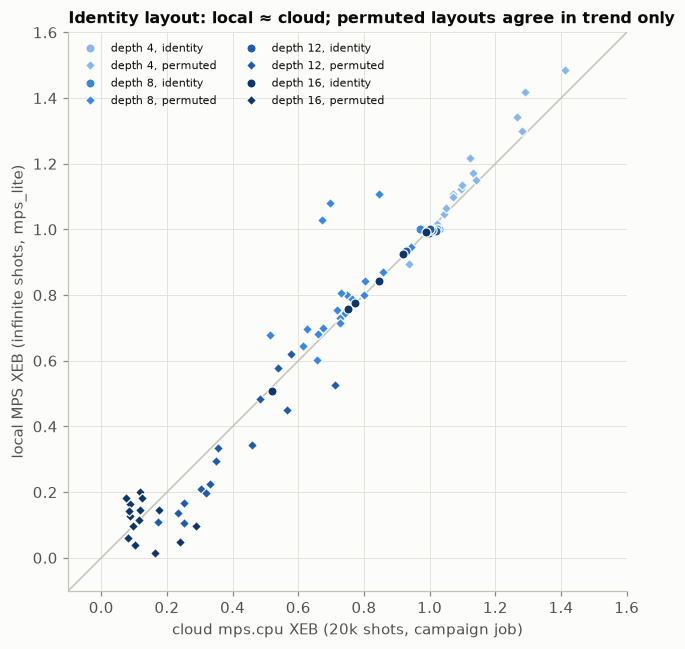

In [5]:
ramp = {4: "#86b6ef", 8: "#3987e5", 12: "#1c5cab", 16: "#0d366b"}   # ordinal: depth
fig, ax = plt.subplots(figsize=(6.4, 6.0))
ax.plot([-0.1, 1.6], [-0.1, 1.6], color=C.AXIS, lw=1, zorder=1)
for d, col in ramp.items():
    for shape, sel, lab in (("o", lambda r: r["cfg"][0] == "id", "identity"), ("D", lambda r: r["cfg"][0] == "perm", "permuted")):
        pts = [r for r in paired if r["depth"] == d and sel(r)]
        ax.plot([r["cloud"] for r in pts], [r["xeb"] for r in pts], shape, ms=6 if shape == "o" else 5,
                color=col, mec=C.SURFACE, mew=0.8, zorder=3, label=f"depth {d}, {lab}")
ax.set_xlabel("cloud mps.cpu XEB (20k shots, campaign job)")
ax.set_ylabel("local MPS XEB (infinite shots, mps_lite)")
ax.set_title("Identity layout: local ≈ cloud; permuted layouts agree in trend only", fontsize=10.5)
ax.set_xlim(-0.1, 1.6); ax.set_ylim(-0.1, 1.6); ax.set_aspect("equal")
ax.legend(fontsize=7.5, ncol=2, loc="upper left")
fig.tight_layout(); plt.show()

## 3 · Why a relabelling destroys fidelity at fixed χ

The RCS circuits are 1D brickwork: every two-qubit gate acts on neighbours *in the identity layout*. After a random
relabelling the same gates connect distant sites, the MPS routes them with SWAP chains, and entanglement that used to
cross one cut now crosses many. The exact state shows it directly: below is the bond dimension an MPS would need at
every cut of the chain to keep all but 10⁻³ of the state's weight (the printout also gives the largest entanglement
entropy). At depth 8 the relabelled state itself needs far more than χ = 64; at depth 16 the two profiles nearly
coincide, and the extra damage comes from truncation accumulated along the SWAP routes (summary item 3).

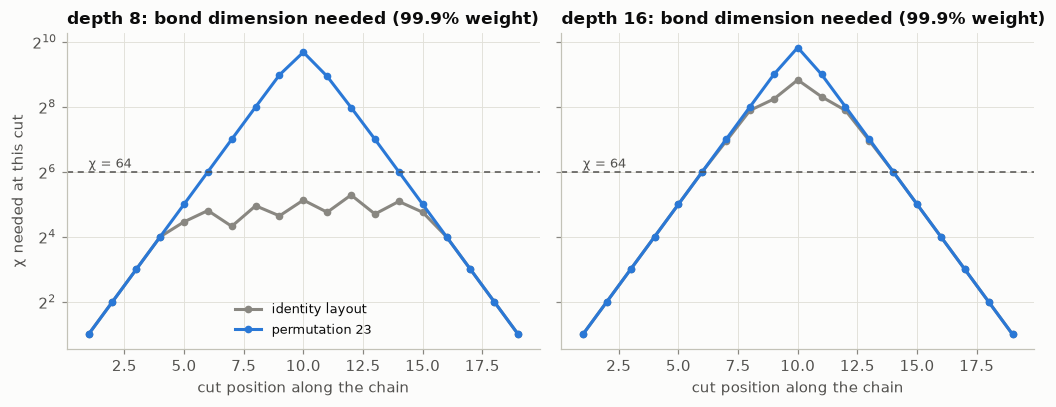

depth  8 identity layout : max entanglement 3.33 bits, cuts needing χ > 64: 0/19, max χ needed 39
depth  8 permutation 23  : max entanglement 8.35 bits, cuts needing χ > 64: 7/19, max χ needed 820
depth 16 identity layout : max entanglement 6.58 bits, cuts needing χ > 64: 7/19, max χ needed 454
depth 16 permutation 23  : max entanglement 9.16 bits, cuts needing χ > 64: 7/19, max χ needed 906


In [6]:
def cut_profile(sv, n=20, keep=1 - 1e-3):
    t = sv.reshape([2] * n).transpose(list(range(n))[::-1])          # axis k = site k
    S, chi_need = [], []
    for k in range(1, n):
        s = np.linalg.svd(t.reshape(2 ** k, -1), compute_uv=False)
        p = s ** 2 / np.sum(s ** 2)
        S.append(float(-np.sum(p[p > 1e-30] * np.log2(p[p > 1e-30]))))
        chi_need.append(int(np.searchsorted(np.cumsum(p), keep) + 1))
    return np.array(S), np.array(chi_need)

prof = {}
for cid in ("rcs_n20_d8_s20263180", "rcs_n20_d16_s20263262"):
    c = next(x for x in circs if x["id"] == cid)
    sv = np.asarray(Statevector.from_instruction(rcs_circuit(20, c["depth"], c["seed"])).data)
    prof[(c["depth"], "identity layout")] = cut_profile(sv)
    prof[(c["depth"], "permutation 23")] = cut_profile(permute_state(sv, perm_of(20, 23)))
fig, axs = plt.subplots(1, 2, figsize=(9.6, 3.8), sharey=True)
for ax, d in zip(axs, (8, 16)):
    for lab, col in (("identity layout", C.NEUTRAL), ("permutation 23", C.BLUE)):
        ax.plot(range(1, 20), prof[(d, lab)][1], "-o", ms=4, color=col, label=lab)
    ax.axhline(64, color=C.INK_2, lw=1, ls=(0, (4, 3))); ax.text(1, 70, "χ = 64", fontsize=8.5, color=C.INK_2)
    ax.set_yscale("log", base=2); ax.set_xlabel("cut position along the chain")
    ax.set_title(f"depth {d}: bond dimension needed (99.9% weight)")
axs[0].set_ylabel("χ needed at this cut"); axs[0].legend(fontsize=8.5, loc="lower center")
fig.tight_layout(); plt.show()
for (d, lab), (S, need) in prof.items():
    print(f"depth {d:2d} {lab:16s}: max entanglement {S.max():.2f} bits, cuts needing χ > 64: {int(np.sum(need > 64))}/19, "
          f"max χ needed {need.max()}")

## 4 · XEB is not fidelity

For every local run we know both the normalized XEB (what the campaign scored) and the true state fidelity F.
Under the identity layout XEB tracks F closely while F is high (it runs somewhat above F on the deepest circuits);
under layout damage XEB stays far above F — and on shallow
circuits truncation *concentrates* probability on already-likely bitstrings, pushing XEB **above 1**, the exact
sampler's score. The campaign's cloud rows show the same: per-circuit XEB above 1 under permutation.

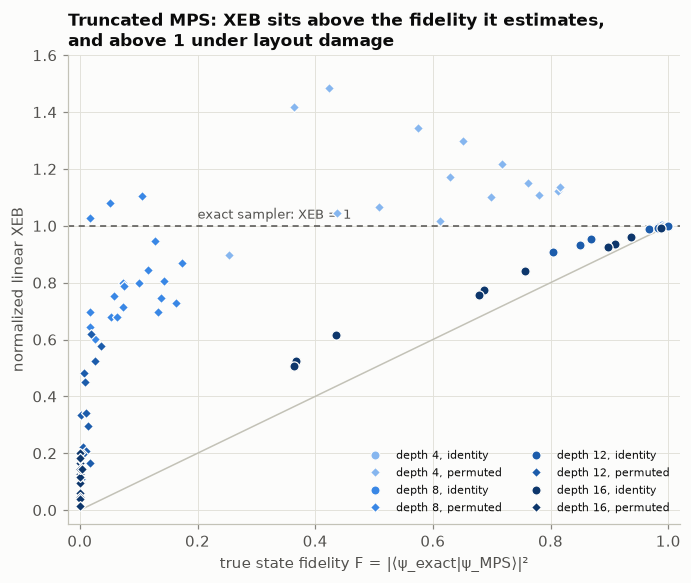

In [7]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.plot([0, 1], [0, 1], color=C.AXIS, lw=1, zorder=1)
ax.axhline(1.0, color=C.INK_2, lw=1, ls=(0, (4, 3))); ax.text(0.20, 1.025, "exact sampler: XEB = 1", fontsize=8.5, color=C.INK_2)
for d, col in ramp.items():
    for shape, sel in (("o", lambda r: r["cfg"][0] == "id"), ("D", lambda r: r["cfg"][0] == "perm")):
        pts = [r for r in results if r["depth"] == d and sel(r)]
        ax.plot([r["fid"] for r in pts], [r["xeb"] for r in pts], shape, ms=6 if shape == "o" else 5, color=col,
                mec=C.SURFACE, mew=0.8, zorder=3, label=f"depth {d}, {'identity' if shape == 'o' else 'permuted'}")
ax.set_xlabel("true state fidelity F = |⟨ψ_exact|ψ_MPS⟩|²"); ax.set_ylabel("normalized linear XEB")
ax.set_title("Truncated MPS: XEB sits above the fidelity it estimates,\nand above 1 under layout damage", fontsize=11)
ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.05, 1.6)
ax.legend(fontsize=7.5, ncol=2, loc="lower right")
fig.tight_layout(); plt.show()

In [8]:
ident = [r for r in results if r["cfg"][0] == "id"]
perm_r = [r for r in results if r["cfg"][0] == "perm"]
over1_local = [r for r in results if r["xeb"] > 1.05]
def nq(cid):
    return int(cid.split("_n")[1].split("_")[0])
perm_rows = [(k, i, v) for (k, i), v in cloud.items() if k[0] == "perm"]          # one row per (config, circuit)
id_rows = [(k, i, v) for (k, i), v in cloud.items() if k[0] == "id"]
over_rows = sorted([t for t in perm_rows if t[2] > 1.05], key=lambda t: -t[2])
like = [t for t in perm_rows if t[0] in sim_cfgs and nq(t[1]) == 20]
low_id = [r for r in ident if r["fid"] < 0.99]; low_pm = [r for r in perm_r if r["fid"] < 0.99]
display(Markdown(
    f"- Runs with F < 0.99 (truncation actually bites): median XEB − F = **{np.median([r['xeb'] - r['fid'] for r in low_id]):+.3f}** "
    f"for the identity layout ({len(low_id)} runs, depths {sorted({r['depth'] for r in low_id})}) and "
    f"**{np.median([r['xeb'] - r['fid'] for r in low_pm]):+.3f}** for permuted layouts ({len(low_pm)} runs). XEB overstated F in "
    f"{sum(r['xeb'] > r['fid'] for r in low_id + low_pm)} of {len(low_id) + len(low_pm)} such runs. Over all runs, including the "
    f"exact ones: identity {np.median([r['xeb'] - r['fid'] for r in ident]):+.3f} ({len(ident)} runs), permuted "
    f"{np.median([r['xeb'] - r['fid'] for r in perm_r]):+.3f} ({len(perm_r)} runs).\n"
    f"- Local runs with XEB > 1.05: **{len(over1_local)}**, of which {sum(r['cfg'][0] == 'perm' for r in over1_local)} are "
    f"permuted-layout runs; depths {dict(sorted(collections.Counter(r['depth'] for r in over1_local).items()))}; "
    f"their true fidelity ranges {min(r['fid'] for r in over1_local):.2f}–{max(r['fid'] for r in over1_local):.2f}.\n"
    f"- Cloud rows (campaign jobs, one per configuration × circuit, all permutation rounds except flywheel round 4, all "
    f"circuit sizes): **{len(over_rows)} of {len(perm_rows)}** permuted-layout rows exceed 1.05 (max {over_rows[0][2]:.3f}; "
    f"{len({t[1] for t in over_rows})} distinct circuits, {min(nq(t[1]) for t in over_rows)}–{max(nq(t[1]) for t in over_rows)} "
    f"qubits), against {sum(t[2] > 1.05 for t in id_rows)} of {len(id_rows)} identity-layout rows (max "
    f"{max(t[2] for t in id_rows):.3f}). Restricted to the 20-qubit circuits and the permutation configurations simulated "
    f"locally: {sum(t[2] > 1.05 for t in like)} of {len(like)} (max {max(t[2] for t in like):.3f})."))

- Runs with F < 0.99 (truncation actually bites): median XEB − F = **+0.078** for the identity layout (17 runs, depths [8, 12, 16]) and **+0.476** for permuted layouts (65 runs). XEB overstated F in 82 of 82 such runs. Over all runs, including the exact ones: identity +0.001 (43 runs), permuted +0.476 (65 runs).
- Local runs with XEB > 1.05: **14**, of which 14 are permuted-layout runs; depths {4: 12, 8: 2}; their true fidelity ranges 0.05–0.82.
- Cloud rows (campaign jobs, one per configuration × circuit, all permutation rounds except flywheel round 4, all circuit sizes): **51 of 288** permuted-layout rows exceed 1.05 (max 2.134; 10 distinct circuits, 20–26 qubits), against 0 of 72 identity-layout rows (max 1.029). Restricted to the 20-qubit circuits and the permutation configurations simulated locally: 12 of 65 (max 1.413).

## 5 · A structure-aware proposer undoes the damage in one step

The flywheel's permutation family proposed random seeds (11, 23, 37, 211, 252). A proposer that reads the circuit
would instead order qubits to reduce the *bandwidth* of the interaction graph (qubits = nodes, two-qubit gates =
edges) — e.g. with reverse Cuthill–McKee, a standard bandwidth-reduction heuristic. Applied to the scrambled circuit it finds a bandwidth-1 ordering (for 1D brickwork
that is the chain or its mirror), and fidelity returns. It also shows why this family had **no upside** on this suite:
the identity layout is already optimal for 1D brickwork; on 2D grids and heavy-hex layouts — the layouts of the
hardware claims Track 2 targets — no bandwidth-1 ordering exists, so the ordering must be chosen and benchmarked.

In [9]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import reverse_cuthill_mckee
def interaction_graph(qc):
    e = {tuple(sorted(qc.find_bit(q).index for q in i.qubits)) for i in qc.data if len(i.qubits) == 2}
    r, c = zip(*e)
    return coo_matrix((np.ones(2 * len(e)), (r + c, c + r)), shape=(qc.num_qubits,) * 2).tocsr(), e
def bandwidth(edges, pos):
    return max(abs(pos[a] - pos[b]) for a, b in edges)

rows, rcm_bw = [], []
for cid in ("rcs_n20_d8_s20263180", "rcs_n20_d16_s20263262"):
    c = next(x for x in circs if x["id"] == cid)
    qc = rcs_circuit(20, c["depth"], c["seed"]); sv = np.asarray(Statevector.from_instruction(qc).data)
    for seed in (23, 211):
        pi = perm_of(20, seed); scr = permuted(qc, pi); ref = permute_state(sv, pi)
        G, edges = interaction_graph(scr)
        order = [int(x) for x in reverse_cuthill_mckee(G, symmetric_mode=True)]   # site order proposed
        relabel = [0] * 20
        for new_site, old_site in enumerate(order):
            relabel[old_site] = new_site
        fixed = permuted(scr, relabel); ref_fixed = permute_state(ref, relabel)
        out = {}
        for lab, circ, r_sv in (("scrambled", scr, ref), ("RCM-reordered", fixed, ref_fixed)):
            v = MPS(20, 64).run(gates_from_qiskit(circ)).to_statevector()
            out[lab] = (normalized_xeb(np.abs(v) ** 2, np.abs(r_sv) ** 2), float(abs(np.vdot(r_sv, v)) ** 2))
        bw_s = bandwidth(edges, {q: q for q in range(20)}); bw_f = bandwidth(edges, relabel); rcm_bw.append(bw_f)
        base = next(r for r in results if r["id"] == cid and r["cfg"] == ("id", 64, 64))
        rows.append(f"| {cid} | {seed} | {bw_s} → {bw_f} | {out['scrambled'][0]:.3f} / {out['scrambled'][1]:.3f} | "
                    f"{out['RCM-reordered'][0]:.3f} / {out['RCM-reordered'][1]:.3f} | {base['xeb']:.3f} / {base['fid']:.3f} |")
display(Markdown("χ = 64 throughout. XEB / F.\n\n| circuit | scramble seed | graph bandwidth | scrambled | after RCM | identity layout |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(rows)))

χ = 64 throughout. XEB / F.

| circuit | scramble seed | graph bandwidth | scrambled | after RCM | identity layout |
|---|---|---|---|---|---|
| rcs_n20_d8_s20263180 | 23 | 18 → 1 | 0.680 / 0.053 | 1.000 / 1.000 | 1.000 / 1.000 |
| rcs_n20_d8_s20263180 | 211 | 18 → 1 | 0.729 / 0.163 | 1.000 / 1.000 | 1.000 / 1.000 |
| rcs_n20_d16_s20263262 | 23 | 18 → 1 | 0.097 / 0.000 | 0.758 / 0.679 | 0.758 / 0.679 |
| rcs_n20_d16_s20263262 | 211 | 18 → 1 | 0.145 / 0.001 | 0.758 / 0.679 | 0.758 / 0.679 |

## What this establishes

In [10]:
idg = [r for r in paired if r["cfg"][0] == "id"]; pg = [r for r in paired if r["cfg"][0] == "perm"]
display(Markdown(f"""
1. **The campaign suite is reproducible from code alone.** {qpy_ok}/{len(circs)} regenerated circuits and {truth_ok}/{len(circs)} exact
   truth files are byte-identical to the frozen manifest (the 20-qubit train/val circuits; this notebook keeps every simulation
   at ≤ 20 qubits, so the 24- and 26-qubit circuits are out of its scope).
2. **Identity-layout cloud results are reproduced closely by an independent MPS** (median |local − cloud|
   {np.median([abs(r['xeb'] - r['cloud']) for r in idg]):.3f}, {sum(abs(r['xeb'] - r['cloud']) <= 2 * r['se'] for r in idg)} of {len(idg)} within two
   shot-noise standard errors). **Permuted layouts agree in trend only** (median |difference|
   {np.median([abs(r['xeb'] - r['cloud']) for r in pg]):.3f}, max {max(abs(r['xeb'] - r['cloud']) for r in pg):.3f}; {sum(abs(r['xeb'] - r['cloud']) <= 2 * r['se'] for r in pg)} of
   {len(pg)} within two SE): the cloud simulator's SWAP routing and truncation order are not public. The Pearson
   r = {np.corrcoef(lx, cx)[0, 1]:.3f} over all {len(paired)} pairs mainly reflects the separation between the two groups.
3. **The permutation collapse is real physics, not a scoring artefact.** At depth 8 the relabelled state itself needs far
   more than χ = 64 at the central cuts (section 3). At depth 16 both layouts already exceed χ = 64 at the same cuts; the
   extra damage is truncation accumulated along the SWAP routes that carry each long-range gate (summed discarded weight at
   depth 16, χ = 64: median {np.median([r['discarded'] for r in results if r['depth'] == 16 and r['cfg'] == ('id', 64, 64)]):.2f}
   identity vs {np.median([r['discarded'] for r in results if r['depth'] == 16 and r['cfg'][0] == 'perm' and r['chi'] == 64]):.2f} permuted).
4. **Linear XEB is a biased fidelity proxy for truncated simulators.** Where truncation bites (F < 0.99) it overstates fidelity
   by a median {np.median([r['xeb'] - r['fid'] for r in low_id]):+.2f} (identity) and {np.median([r['xeb'] - r['fid'] for r in low_pm]):+.2f} (permuted),
   and under layout damage it can exceed the exact sampler. For an automated attack loop this matters twice: an
   optimizer that maximizes XEB can be rewarded for truncation artefacts, and a claimed XEB is not evidence of faithful
   simulation (Gao et al., arXiv:2112.01657). The 3-month gate should score fidelity directly at verification scale and
   flag per-circuit XEB above 1 as suspect rather than as improvement.
5. **Layout is a lever only where structure allows it.** A bandwidth-reduction heuristic (RCM) recovers the identity-layout
   result in one step, which is easy for a chain; on 1D brickwork there was nothing to gain, so the flywheel's random-seed
   permutation family could only lose. On 2D and heavy-hex layouts no bandwidth-1 ordering exists, so the ordering must
   be chosen and benchmarked against the standard snake baseline (notebook 05 §2c shows the all-to-all extreme).
"""))


1. **The campaign suite is reproducible from code alone.** 13/13 regenerated circuits and 13/13 exact
   truth files are byte-identical to the frozen manifest (the 20-qubit train/val circuits; this notebook keeps every simulation
   at ≤ 20 qubits, so the 24- and 26-qubit circuits are out of its scope).
2. **Identity-layout cloud results are reproduced closely by an independent MPS** (median |local − cloud|
   0.004, 22 of 25 within two
   shot-noise standard errors). **Permuted layouts agree in trend only** (median |difference|
   0.043, max 0.383; 18 of
   65 within two SE): the cloud simulator's SWAP routing and truncation order are not public. The Pearson
   r = 0.975 over all 90 pairs mainly reflects the separation between the two groups.
3. **The permutation collapse is real physics, not a scoring artefact.** At depth 8 the relabelled state itself needs far
   more than χ = 64 at the central cuts (section 3). At depth 16 both layouts already exceed χ = 64 at the same cuts; the
   extra damage is truncation accumulated along the SWAP routes that carry each long-range gate (summed discarded weight at
   depth 16, χ = 64: median 0.37
   identity vs 8.33 permuted).
4. **Linear XEB is a biased fidelity proxy for truncated simulators.** Where truncation bites (F < 0.99) it overstates fidelity
   by a median +0.08 (identity) and +0.48 (permuted),
   and under layout damage it can exceed the exact sampler. For an automated attack loop this matters twice: an
   optimizer that maximizes XEB can be rewarded for truncation artefacts, and a claimed XEB is not evidence of faithful
   simulation (Gao et al., arXiv:2112.01657). The 3-month gate should score fidelity directly at verification scale and
   flag per-circuit XEB above 1 as suspect rather than as improvement.
5. **Layout is a lever only where structure allows it.** A bandwidth-reduction heuristic (RCM) recovers the identity-layout
   result in one step, which is easy for a chain; on 1D brickwork there was nothing to gain, so the flywheel's random-seed
   permutation family could only lose. On 2D and heavy-hex layouts no bandwidth-1 ordering exists, so the ordering must
   be chosen and benchmarked against the standard snake baseline (notebook 05 §2c shows the all-to-all extreme).


## Checks

In [11]:
checks = [
    (f"regenerated circuits byte-identical to the manifest (QPY sha256): {qpy_ok}/{len(circs)}", qpy_ok == len(circs)),
    (f"regenerated exact-truth files byte-identical to the manifest: {truth_ok}/{len(circs)}", truth_ok == len(circs)),
    ("RCM restores bandwidth 1 on every scrambled circuit tried", all(b == 1 for b in rcm_bw)),
    ("every local run with XEB > 1.05 is a permuted-layout run", all(r["cfg"][0] == "perm" for r in over1_local)),
]
for name, ok in checks:
    print(("PASS  " if ok else "FAIL  ") + name)
print(f"{sum(ok for _, ok in checks)}/{len(checks)} checks pass; notebook runtime {time.time() - T0:.0f}s")
assert all(ok for _, ok in checks)

PASS  regenerated circuits byte-identical to the manifest (QPY sha256): 13/13
PASS  regenerated exact-truth files byte-identical to the manifest: 13/13
PASS  RCM restores bandwidth 1 on every scrambled circuit tried
PASS  every local run with XEB > 1.05 is a permuted-layout run
4/4 checks pass; notebook runtime 414s
